<a href="https://colab.research.google.com/github/LetheeshBalaji/DEEP-LEARNING/blob/main/24BAD063_Exp_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Roll Number: YOUR ROLL NUMBER
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Shape: (60000, 28, 28)
Testing Shape: (10000, 28, 28)
Data Type: uint8
Image Dimensions: (28, 28)
After Reshaping:
Training Data: (60000, 784)
Testing Data: (10000, 784)
Pixel Range: 0.0 to 1.0


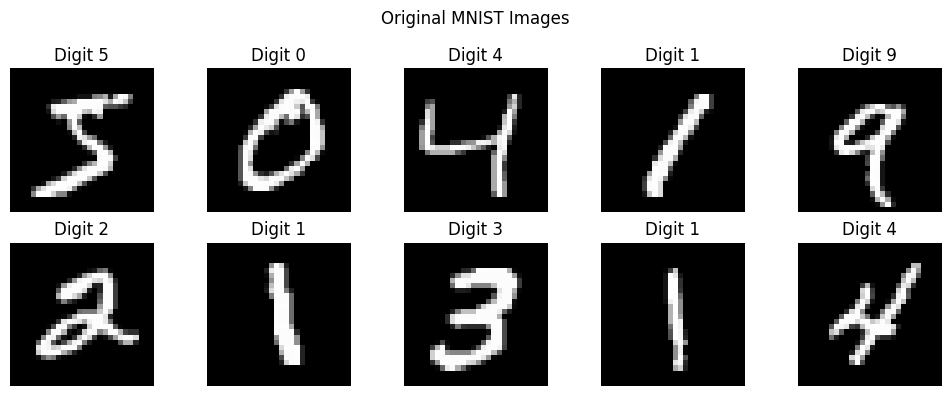

In [ ]:
# PART A: DATASET PREPARATION

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist

# Student Details
roll_no = "YOUR ROLL NUMBER"
print("Roll Number:", roll_no)

# Load MNIST Dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Explore Dataset
print("Training Shape:", x_train.shape)
print("Testing Shape:", x_test.shape)
print("Data Type:", x_train.dtype)
print("Image Dimensions:", x_train[0].shape)

# Normalize Images
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Reshape Images into 1D Vectors
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# Input and Target Data
x_train_target = x_train
x_test_target = x_test

print("After Reshaping:")
print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)
print("Pixel Range:", x_train.min(), "to", x_train.max())

# Display Original Images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_train[i].reshape(28, 28), cmap='gray')
    plt.title("Digit " + str(y_train[i]))
    plt.axis('off')

plt.suptitle("Original MNIST Images")
plt.tight_layout()
plt.show()

In [ ]:
# PART B: AUTOENCODER MODEL

from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

# Define Input Layer
input_layer = Input(shape=(784,))

# Encoder
encoder_layer1 = Dense(128, activation='relu')(input_layer)
encoder_layer2 = Dense(64, activation='relu')(encoder_layer1)

# Bottleneck Layer
bottleneck = Dense(32, activation='relu')(encoder_layer2)

# Create Encoder
encoder = Model(input_layer, bottleneck, name="Encoder")

# Decoder
decoder_input = Input(shape=(32,))
decoder_layer1 = Dense(64, activation='relu')(decoder_input)
decoder_layer2 = Dense(128, activation='relu')(decoder_layer1)
decoder_output = Dense(784, activation='sigmoid')(decoder_layer2)

# Create Decoder
decoder = Model(decoder_input, decoder_output, name="Decoder")

# Combine Encoder and Decoder
autoencoder_output = decoder(encoder(input_layer))
autoencoder = Model(input_layer, autoencoder_output, name="Autoencoder")

# Compile Model
autoencoder.compile(
    optimizer='adam',
    loss='mse'
)

# Display Model Architecture
autoencoder.summary()

# Display Encoder and Decoder
print("\nENCODER SUMMARY")
encoder.summary()

print("\nDECODER SUMMARY")
decoder.summary()

Model: "Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder (Functional)            │ (None, 32)             │       110,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder (Functional)            │ (None, 784)            │       111,568 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)


ENCODER SUMMARY


... (7 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,568 (435.81 KB)

 Trainable params: 111,568 (435.81 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - loss: 0.0623 - val_loss: 0.0369
Epoch 2/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.0306 - val_loss: 0.0248
Epoch 3/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0228 - val_loss: 0.0204
Epoch 4/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 0.0199 - val_loss: 0.0185
Epoch 5/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - loss: 0.0183 - val_loss: 0.0171
Epoch 6/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0170 - val_loss: 0.0162
Epoch 7/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.0159 - val_loss: 0.0151
Epoch 8/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - loss: 0.0151 - val_loss: 0.0144
Epoch 9/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 0.0144 - val_loss: 0.0137
Epoch 10/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0138 - val_loss: 0.0132
Epoch 11/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0133 - val_loss: 0.0128
Epoch 12/20
235/235 ━━━━━━━━━━━━━━━━━━━━

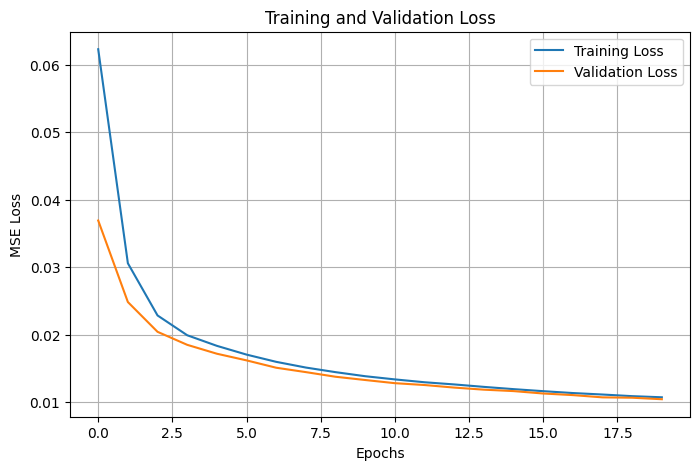

Test Reconstruction MSE: 0.01039524283260107
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step


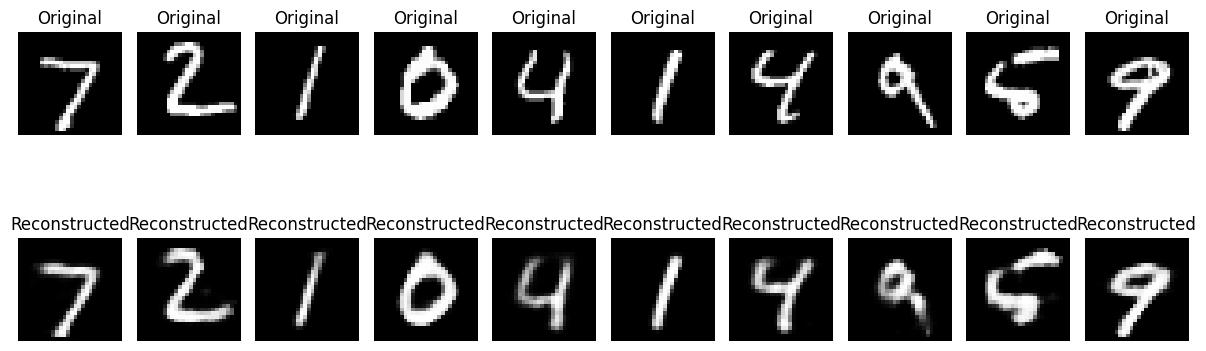

In [ ]:
# PART C: MODEL TRAINING AND EVALUATION

# Train Autoencoder
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=20,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)

# Display Training and Validation Loss
print("Training Loss:", history.history['loss'][-1])
print("Validation Loss:", history.history['val_loss'][-1])

# Plot Loss Graph
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid()
plt.show()

# Evaluate Model
test_loss = autoencoder.evaluate(x_test, x_test, verbose=0)
print("Test Reconstruction MSE:", test_loss)

# Reconstruct Test Images
reconstructed = autoencoder.predict(x_test[:10])

# Compare Original and Reconstructed Images
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 10, i+1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(2, 10, i+11)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.tight_layout()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Original Data Dimensions: (10000, 784)
Compressed Data Dimensions: (10000, 32)
Original Features: 784
Compressed Features: 32
Dimensionality Reduction: 95.91836734693877 %


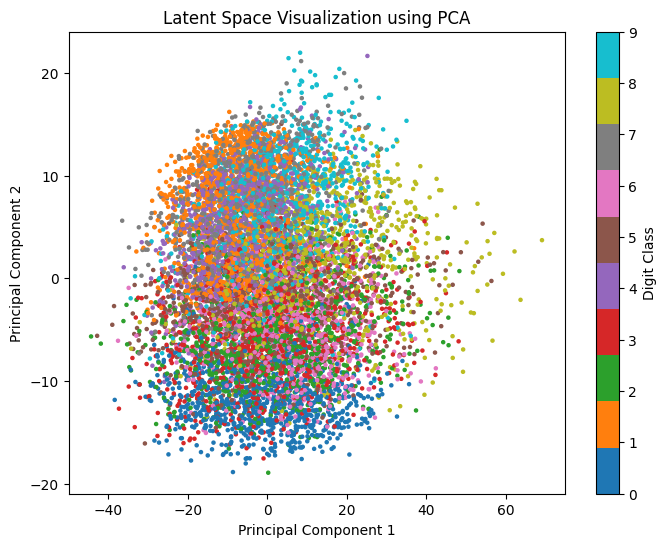

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step


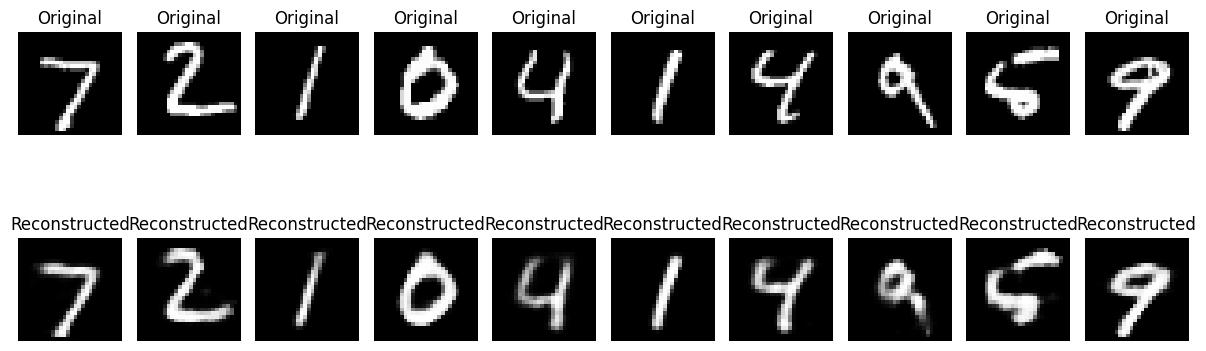


FINAL OBSERVATIONS
1. Original MNIST images contain 784 features.
2. Encoder compresses images into 32 features.
3. Dimensionality is reduced by 95.92%.
4. PCA visualizes latent features in 2D.
5. Decoder reconstructs original images.
6. Reconstruction performance is evaluated using MSE.

Autoencoder implementation completed successfully!


In [ ]:
# PART D: DIMENSIONALITY REDUCTION AND VISUALIZATION

from sklearn.decomposition import PCA

# Extract Latent Space Representations
latent_features = encoder.predict(x_test)

print("Original Data Dimensions:", x_test.shape)
print("Compressed Data Dimensions:", latent_features.shape)

# Compare Dimensions
original = x_test.shape[1]
compressed = latent_features.shape[1]

reduction = ((original - compressed) / original) * 100

print("Original Features:", original)
print("Compressed Features:", compressed)
print("Dimensionality Reduction:", reduction, "%")

# Visualize Latent Representations using PCA
pca = PCA(n_components=2)
latent_2d = pca.fit_transform(latent_features)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    latent_2d[:, 0],
    latent_2d[:, 1],
    c=y_test,
    cmap='tab10',
    s=5
)

plt.colorbar(scatter, label='Digit Class')
plt.title("Latent Space Visualization using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

# Reconstruct Selected Test Samples
samples = x_test[:10]
encoded = encoder.predict(samples)
decoded = decoder.predict(encoded)

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 10, i+1)
    plt.imshow(samples[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(2, 10, i+11)
    plt.imshow(decoded[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.tight_layout()
plt.show()

# Save Models
autoencoder.save("mnist_autoencoder.keras")
encoder.save("mnist_encoder.keras")

# Final Observations
print("\nFINAL OBSERVATIONS")
print("1. Original MNIST images contain 784 features.")
print("2. Encoder compresses images into 32 features.")
print("3. Dimensionality is reduced by 95.92%.")
print("4. PCA visualizes latent features in 2D.")
print("5. Decoder reconstructs original images.")
print("6. Reconstruction performance is evaluated using MSE.")

print("\nAutoencoder implementation completed successfully!")